# Decision Trees and Random Forests — Python companion
**Machine Learning for Biomedical Data (MLBD), Week 6**

This notebook follows the R lecture `lectures/week6/trees.Rmd`, replacing `rpart` and `randomForest` with scikit-learn.

| R | scikit-learn |
|---|---|
| `rpart(y ~ ., method = "anova")` | `DecisionTreeRegressor` |
| `rpart(y ~ .)` with a factor outcome | `DecisionTreeClassifier` |
| `cp` (complexity parameter) | `ccp_alpha` (cost-complexity pruning) |
| `minsplit`, `minbucket` | `min_samples_split`, `min_samples_leaf` |
| `randomForest(ntree, mtry, nodesize)` | `RandomForestClassifier(n_estimators, max_features, min_samples_leaf)` |
| OOB error | `oob_score=True` |
| `importance(type = 1)` | `sklearn.inspection.permutation_importance` |

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LOCAL = "../data/"
REMOTE = "https://raw.githubusercontent.com/wevanjohnson/2026_Fall_MLBD/main/python/data/"
DATA = LOCAL if os.path.exists(LOCAL) else REMOTE

from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance

## Motivating example: olive oil
Predict the region from 8 fatty acids.

In [2]:
olive = pd.read_csv(DATA + "olive.csv")
X_ol, y_ol = olive.drop(columns="region"), olive["region"]
print(y_ol.value_counts())
olive.head()

region
Southern Italy    323
Northern Italy    151
Sardinia           98
Name: count, dtype: int64


,region,palmitic,palmitoleic,stearic,oleic,linoleic,linolenic,arachidic,eicosenoic
0,Southern Italy,10.75,0.75,2.26,78.23,6.72,0.36,0.60,0.29
1,Southern Italy,10.88,0.73,2.24,77.09,7.81,0.31,0.61,0.29
2,Southern Italy,9.11,0.54,2.46,81.13,5.49,0.31,0.63,0.29
3,Southern Italy,9.66,0.57,2.40,79.52,6.19,0.50,0.78,0.35
4,Southern Italy,10.51,0.67,2.59,77.71,6.72,0.50,0.80,0.46


A quick kNN fit already predicts well (5-fold CV accuracy by $k$):

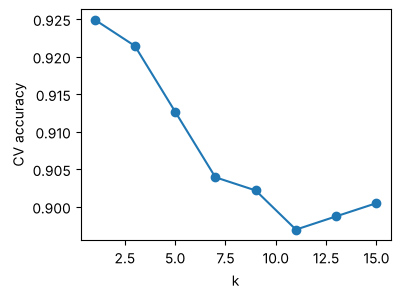

In [3]:
ks = range(1, 16, 2)
acc = [cross_val_score(KNeighborsClassifier(k), X_ol, y_ol, cv=5).mean() for k in ks]
plt.figure(figsize=(4, 3)); plt.plot(ks, acc, "o-"); plt.xlabel("k"); plt.ylabel("CV accuracy"); plt.show()

Eicosenoic is only in Southern Italy; linoleic separates Northern Italy from Sardinia:

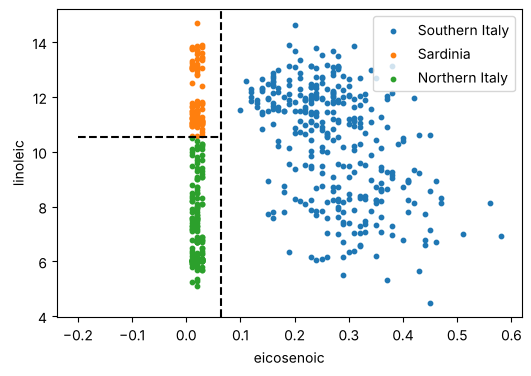

In [4]:
fig, ax = plt.subplots(figsize=(6, 4))
for r in y_ol.unique():
    d = olive[olive.region == r]
    ax.scatter(d.eicosenoic, d.linoleic, s=10, label=r)
ax.axvline(0.065, ls="--", c="k"); ax.plot([-0.2, 0.065], [10.54, 10.54], "k--")
ax.set_xlabel("eicosenoic"); ax.set_ylabel("linoleic"); ax.legend(); plt.show()

A classification tree finds (nearly) the same rule:

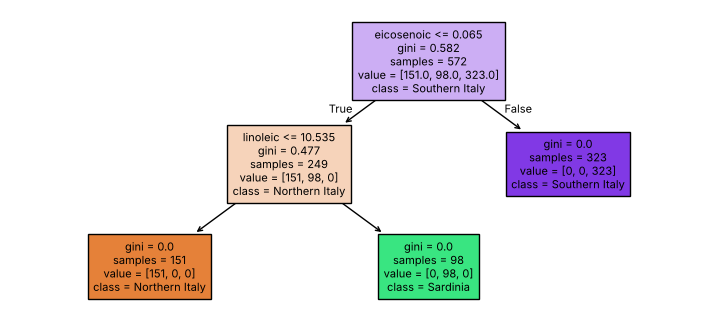

In [5]:
tree_ol = DecisionTreeClassifier(max_depth=2, random_state=0).fit(X_ol, y_ol)
plt.figure(figsize=(9, 4))
plot_tree(tree_ol, feature_names=X_ol.columns, class_names=tree_ol.classes_, filled=True, fontsize=8)
plt.show()

## Regression trees: 2008 polls
$Y$ = poll margin (Obama − McCain), $x$ = day. Note: `rpart`'s `cp` and scikit-learn's `ccp_alpha` are on different scales (`cp` is relative to the root-node error), so the values differ from the slides.

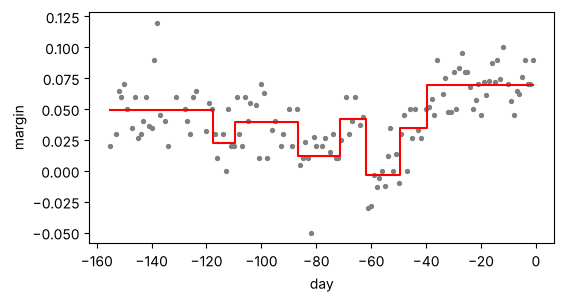

In [6]:
polls = pd.read_csv(DATA + "polls_2008.csv")
Xp, yp = polls[["day"]], polls["margin"]
# rpart's defaults: minsplit = 20, minbucket = 7, cp = 0.01
fit = DecisionTreeRegressor(min_samples_split=20, min_samples_leaf=7,
                            ccp_alpha=0.01 * yp.var(), random_state=0).fit(Xp, yp)
plt.figure(figsize=(6, 3))
plt.scatter(polls.day, polls.margin, s=8, c="grey")
plt.step(polls.day, fit.predict(Xp), c="red", where="mid")
plt.xlabel("day"); plt.ylabel("margin"); plt.show()

With no stopping rule (`cp = 0`, `minsplit = 2` in R), the tree reproduces the data — overfitting:

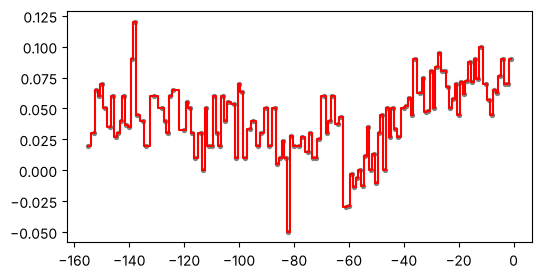

In [7]:
over = DecisionTreeRegressor(random_state=0).fit(Xp, yp)
plt.figure(figsize=(6, 3))
plt.scatter(polls.day, polls.margin, s=8, c="grey")
plt.step(polls.day, over.predict(Xp), c="red", where="mid"); plt.show()

Choose the pruning penalty by cross-validation:

best ccp_alpha: {'ccp_alpha': np.float64(5.187968605071939e-06)}


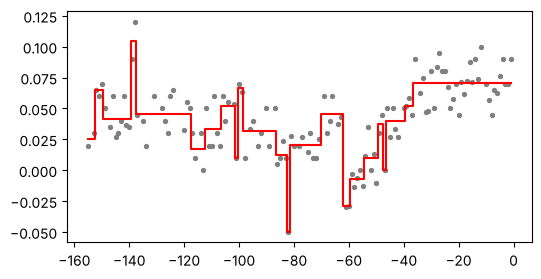

In [8]:
path = DecisionTreeRegressor(random_state=0).cost_complexity_pruning_path(Xp, yp)
alphas = np.unique(path.ccp_alphas)[:-1]
cv = GridSearchCV(DecisionTreeRegressor(random_state=0), {"ccp_alpha": alphas},
                  cv=5, scoring="neg_mean_squared_error").fit(Xp, yp)
print("best ccp_alpha:", cv.best_params_)
plt.figure(figsize=(6, 3))
plt.scatter(polls.day, polls.margin, s=8, c="grey")
plt.step(polls.day, cv.predict(Xp), c="red", where="mid"); plt.show()

## Classification trees: digits 2 vs. 7
scikit-learn uses the Gini index by default (`criterion="entropy"` for entropy).

In [9]:
train = pd.read_csv(DATA + "mnist_27_train.csv"); test = pd.read_csv(DATA + "mnist_27_test.csv")
Xtr, ytr = train[["x_1", "x_2"]], train["y"].astype(str)
Xte, yte = test[["x_1", "x_2"]], test["y"].astype(str)

true_p = pd.read_csv(DATA + "mnist_27_true_p.csv")
g1 = np.sort(true_p["x_1"].unique()); g2 = np.sort(true_p["x_2"].unique())

def plot_cond_prob(p, ax, title=""):
    tp = true_p.assign(p=p).pivot(index="x_2", columns="x_1", values="p")
    ax.imshow(tp.values, origin="lower", extent=[g1.min(), g1.max(), g2.min(), g2.max()],
              aspect="auto", cmap="RdBu", vmin=0, vmax=1)
    ax.contour(tp.columns, tp.index, tp.values, levels=[0.5], colors="black")
    ax.set_title(title); ax.set_xlabel("x_1"); ax.set_ylabel("x_2")

In [10]:
path = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(Xtr, ytr)
cv_tree = GridSearchCV(DecisionTreeClassifier(random_state=0),
                       {"ccp_alpha": np.unique(path.ccp_alphas)[:-1]}, cv=5).fit(Xtr, ytr)
print("test accuracy:", round(cv_tree.score(Xte, yte), 3))

test accuracy: 0.815


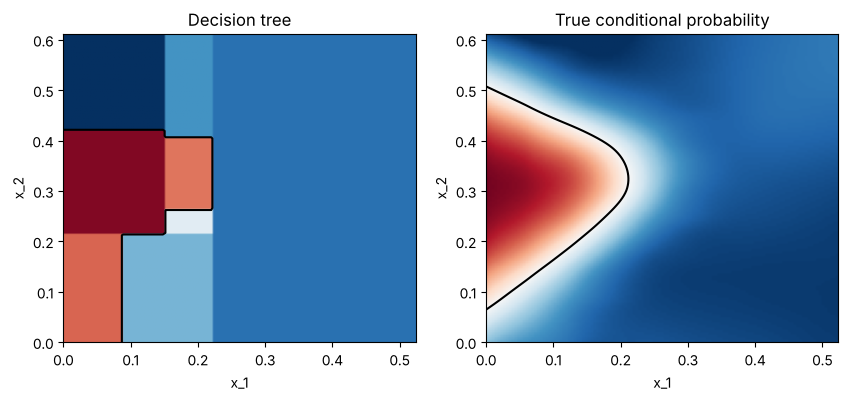

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
plot_cond_prob(cv_tree.predict_proba(true_p[["x_1", "x_2"]])[:, 1], ax[0], "Decision tree")
plot_cond_prob(true_p["p"], ax[1], "True conditional probability"); plt.show()

## Random forests
Two sources of randomness: bootstrap the rows, and try only `max_features` (R: `mtry`) predictors at **each split**. With one predictor (polls), a forest is just bagging.

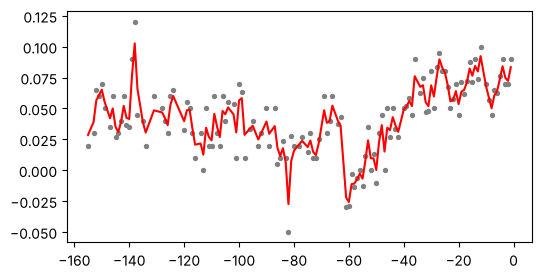

In [12]:
rf_p = RandomForestRegressor(n_estimators=500, random_state=0).fit(Xp, yp)
plt.figure(figsize=(6, 3))
plt.scatter(polls.day, polls.margin, s=8, c="grey")
plt.plot(polls.day, rf_p.predict(Xp), c="red"); plt.show()

Error vs. number of trees, using the out-of-bag (OOB) error:

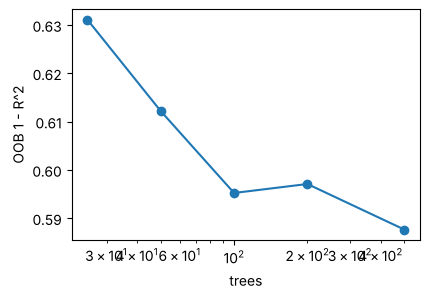

In [13]:
ns = [25, 50, 100, 200, 500]
oob = [1 - RandomForestRegressor(n_estimators=n, oob_score=True, random_state=0)
           .fit(Xp, yp).oob_score_ for n in ns]
plt.figure(figsize=(4.5, 3)); plt.plot(ns, oob, "o-"); plt.xscale("log")
plt.xlabel("trees"); plt.ylabel("OOB 1 - R^2"); plt.show()

Digits: a forest, then tuning the minimum leaf size (R: `nodesize`):

In [14]:
rf = RandomForestClassifier(n_estimators=500, random_state=0).fit(Xtr, ytr)
print("test accuracy (default):", round(rf.score(Xte, yte), 3))
cv_rf = GridSearchCV(RandomForestClassifier(n_estimators=300, max_features=2, random_state=0),
                     {"min_samples_leaf": [1, 11, 21, 31, 41, 51]}, cv=5).fit(Xtr, ytr)
print("best:", cv_rf.best_params_, " test accuracy:", round(cv_rf.score(Xte, yte), 3))

test accuracy (default): 0.825


best: {'min_samples_leaf': 11}  test accuracy: 0.835


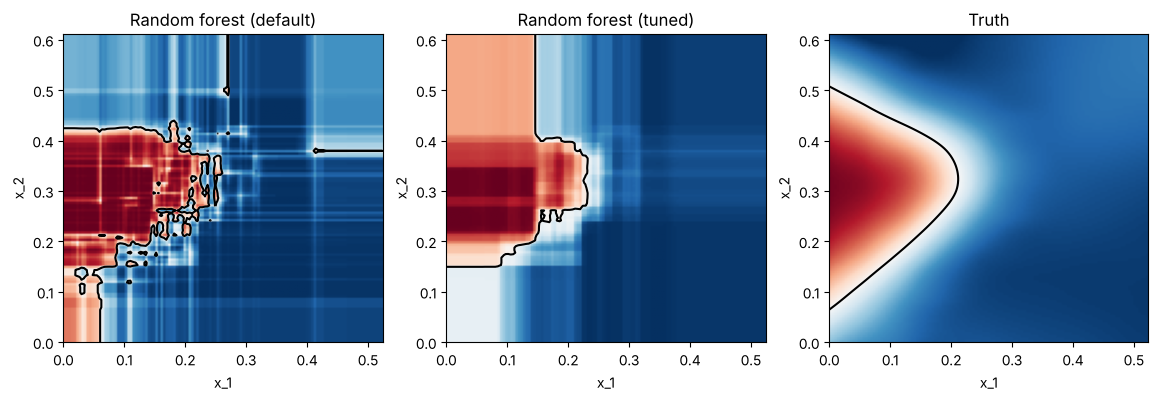

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
plot_cond_prob(rf.predict_proba(true_p[["x_1", "x_2"]])[:, 1], ax[0], "Random forest (default)")
plot_cond_prob(cv_rf.predict_proba(true_p[["x_1", "x_2"]])[:, 1], ax[1], "Random forest (tuned)")
plot_cond_prob(true_p["p"], ax[2], "Truth"); plt.show()

## Back to olive oil: OOB error and variable importance
`feature_importances_` is the impurity (Gini) importance; `permutation_importance` shuffles one feature at a time. Here we compute it on the training data for simplicity; in practice use held-out data.

OOB error: 0.0


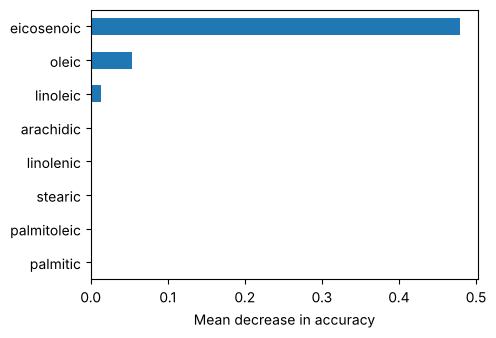

cor(oleic, linoleic): -0.85


In [16]:
rf_ol = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=0).fit(X_ol, y_ol)
print("OOB error:", round(1 - rf_ol.oob_score_, 4))
pi = permutation_importance(rf_ol, X_ol, y_ol, n_repeats=10, random_state=0)
imp = pd.Series(pi.importances_mean, index=X_ol.columns).sort_values()
imp.plot.barh(figsize=(5, 3.5)); plt.xlabel("Mean decrease in accuracy"); plt.show()
print("cor(oleic, linoleic):", round(olive.oleic.corr(olive.linoleic), 2))